# 01 — Data Understanding
## OSMI 2016: Mental Health in Technology-Related Jobs

### Notebook Purpose
This notebook establishes an evidence-based understanding of the supplied 2016 OSMI survey before any substantive cleaning or modelling. It examines the source schema, data quality, response distributions, survey routing, multi-select fields, free-text responses, and potential analytical limitations.

**Boundary:** this notebook profiles and documents the source data. It does not impute values, recode survey responses, create model features, or construct clustering matrices. Those operations are performed in **02 — Data Preparation**.

### Analytical Objective
The project seeks interpretable groups of respondents based on reported workplace mental-health support, psychological safety, and disclosure/career climate. It is not a clinical prediction or diagnostic exercise.

### Planned Clustering Approaches
1. **K-Modes** on categorical response features. K-Modes uses categorical matching dissimilarity; it does not preserve ordinal spacing.
2. **MCA + K-Means**. MCA represents categorical response patterns in a continuous component space, followed by K-Means. MCA treats categories nominally; ordering is not retained unless separately encoded, which is not the design here.
3. **Agglomerative hierarchical clustering + Gower dissimilarity**. Gower accommodates nominal and ordinal feature types. Average linkage is the intended starting point for precomputed Gower dissimilarities; Ward linkage is not appropriate for arbitrary Gower dissimilarities.
4. **HDBSCAN + Gower dissimilarity**. HDBSCAN will use the precomputed Gower distance matrix, subject to implementation support and the quadratic memory cost of pairwise distances.

### Evaluation Principles
Each method will use metrics compatible with its representation. K-Modes cost and repeated-run/resampling stability; MCA-space silhouette, Davies–Bouldin and Calinski–Harabasz; Gower silhouette and dendrogram cophenetic correlation for hierarchical clustering; and DBCV, noise share, persistence and membership strengths for HDBSCAN. Cophenetic correlation evaluates dendrogram fidelity, not the validity of a chosen partition. Raw metric values from different representations will not be treated as directly comparable. Cluster profiling and stability are essential because there are no ground-truth cluster labels.

### Ethical and Interpretive Boundaries
Survey answers are self-reported and historically situated. Personal mental-health diagnoses, treatment, and suspected conditions are sensitive and will not be used as primary clustering features. Resulting groups describe response patterns, not diagnoses, employee suitability, or individual risk. Demographics and other context may be used cautiously for descriptive profiling, not as proxies for health status.

## 1. Environment

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")

# Resolve the repository root whether the notebook is launched from the root or from notebooks/
ROOT = (
    Path.cwd().resolve().parent
    if Path.cwd().resolve().name == "notebooks"
    else Path.cwd().resolve()
)
RAW_FILE = ROOT / "data" / "raw" / "mental-heath-in-tech-2016_20161114.csv"
INTERIM_DIR = ROOT / "data" / "interim"
FIGURES_DIR = ROOT / "reports" / "figures" / "data_understanding"
for directory in (INTERIM_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(RAW_FILE)

print(f"Dataset dimensions: {df_raw.shape[0]:,} respondents x {df_raw.shape[1]:,} variables")
display(df_raw.head())

Dataset dimensions: 1,433 respondents x 63 variables


,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",Do you think that discussing a mental health disorder with your employer would have negative consequences?,Do you think that discussing a physical health issue with your employer would have negative consequences?,Would you feel comfortable discussing a mental health disorder with your coworkers?,Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?,Do you feel that your employer takes mental health as seriously as physical health?,Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?,Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,Do you know local or online resources to seek help for a mental health disorder?,"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?","If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?","If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?","If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?",Do you believe your productivity is ever affected by a mental health issue?,"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",Do you have previous employers?,Have your previous employers provided mental health benefits?,Were you aware of the options for mental health care provided by your previous employers?,Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?,Did your previous employers provide resources to learn more about mental health issues and how to seek help?,Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?,Do you think that discussing a mental health disorder with previous employers would have negative consequences?,Do you think that discussing a physical health issue with previous employers would have negative consequences?,Would you have been willing to discuss a mental health issue with your previous co-workers?,Would you have been willing to discuss a mental health issue with your direct supervisor(s)?,Did you feel that your previous employers took mental health as seriously as physical health?,Did you hear of or observe negative consequences for co-workers with mental health issues in your previous workplaces?,Would you be willing to bring up a physical health issue with a potential employer in an interview?,Why or why not?,Would you bring up a mental health issue with a potential employer in an interview?,Why or why not?.1,Do you feel that being identified as a person with a mental health issue would hurt your career?,Do you think that team members/co-workers would view you more negatively if they knew you suffered from a menta

The dataset file contains **1,433 respondent records and 63 survey variables**.

## 2. Schema Review and Consistent Column Names

In [2]:
# The mapping preserves the original survey wording in the source file while
# providing stable, readable snake_case names for subsequent analysis.
column_name_mapping = {
    "Are you self-employed?": "self_employed",
    "How many employees does your company or organization have?": "company_size",
    "Is your employer primarily a tech company/organization?": "tech_company",
    "Is your primary role within your company related to tech/IT?": "tech_role",
    "Does your employer provide mental health benefits as part of healthcare coverage?": "mh_benefits",
    "Do you know the options for mental health care available under your employer-provided coverage?": "mh_options_awareness",
    "Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?": "mh_formal_discussion",
    "Does your employer offer resources to learn more about mental health concerns and options for seeking help?": "mh_resources_offered",
    "Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?": "mh_anonymity_protected",
    "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:": "mh_medical_leave_ease",
    "Do you think that discussing a mental health disorder with your employer would have negative consequences?": "mh_discussion_consequences",
    "Do you think that discussing a physical health issue with your employer would have negative consequences?": "ph_discussion_consequences",
    "Would you feel comfortable discussing a mental health disorder with your coworkers?": "mh_comfort_coworkers",
    "Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?": "mh_comfort_supervisor",
    "Do you feel that your employer takes mental health as seriously as physical health?": "mh_vs_ph_seriousness",
    "Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?": "observed_mh_consequences",
    "Do you have medical coverage (private insurance or state-provided) which includes treatment of \xa0mental health issues?": "medical_coverage_mh",
    "Do you know local or online resources to seek help for a mental health disorder?": "know_external_resources",
    "If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?": "reveal_mh_clients",
    "If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?": "client_reveal_neg_impact",
    "If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?": "reveal_mh_coworkers",
    "If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?": "coworker_reveal_neg_impact",
    "Do you believe your productivity is ever affected by a mental health issue?": "mh_productivity_affected",
    "If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?": "mh_productivity_pct",
    "Do you have previous employers?": "has_previous_employers",
    "Have your previous employers provided mental health benefits?": "prev_mh_benefits",
    "Were you aware of the options for mental health care provided by your previous employers?": "prev_mh_awareness",
    "Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?": "prev_mh_discussion",
    "Did your previous employers provide resources to learn more about mental health issues and how to seek help?": "prev_mh_resources",
    "Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?": "prev_mh_anonymity",
    "Do you think that discussing a mental health disorder with previous employers would have negative consequences?": "prev_mh_consequences",
    "Do you think that discussing a physical health issue with previous employers would have negative consequences?": "prev_ph_consequences",
    "Would you have been willing to discuss a mental health issue with your previous co-workers?": "prev_willingness_coworkers",
    "Would you have been willing to discuss a mental health issue with your direct supervisor(s)?": "prev_willingness_supervisor",
    "Did you feel that your previous employers took mental health as seriously as physical health?": "prev_mh_vs_ph_seriousness",
    "Did you hear of or observe negative consequences for co-workers with mental health issues in your previous workplaces?": "prev_observed_mh_consequences",
    "Would you be willing to bring up a physical health issue with a potential employer in an interview?": "interview_ph_reveal",
    "Why or why not?": "interview_ph_reveal_why",
    "Would you bring up a mental health issue with a potential employer in an interview?": "interview_mh_reveal",
    "Why or why not?.1": "interview_mh_reveal_why",
    "Do you feel that being identified as a person with a mental health issue would hurt your career?": "mh_hurt_career",
    "Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue?": "coworker_negative_view",
    "How willing would you be to share with friends and family that you have a mental illness?": "share_with_friends_family",
    "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?": "observed_bad_mh_handling",
    "Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?": "observed_bad_handling_impact",
    "Do you have a family history of mental illness?": "family_history_mh",
    "Have you had a mental health disorder in the past?": "past_mh_disorder",
    "Do you currently have a mental health disorder?": "current_mh_disorder",
    "If yes, what condition(s) have you been diagnosed with?": "current_diagnosed_conditions",
    "If maybe, what condition(s) do you believe you have?": "suspected_conditions",
    "Have you been diagnosed with a mental health condition by a medical professional?": "diagnosed_by_pro",
    "If so, what condition(s) were you diagnosed with?": "pro_diagnosed_conditions",
    "Have you ever sought treatment for a mental health issue from a mental health professional?": "sought_mh_treatment",
    "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?": "mh_interference_treated",
    "If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?": "mh_interference_untreated",
    "What is your age?": "age",
    "What is your gender?": "gender",
    "What country do you live in?": "country_live",
    "What US state or territory do you live in?": "us_state_live",
    "What country do you work in?": "country_work",
    "What US state or territory do you work in?": "us_state_work",
    "Which of the following best describes your work position?": "work_position",
    "Do you work remotely?": "work_remote"
}

unmapped_columns = sorted(set(df_raw.columns) - set(column_name_mapping))
unknown_mapping_keys = sorted(set(column_name_mapping) - set(df_raw.columns))
print(f"Mapped columns: {len(column_name_mapping):,} / {df_raw.shape[1]:,}")
print("Unmapped source columns:", unmapped_columns)
print("Mapping keys absent from source:", unknown_mapping_keys)

# Create a separate renamed copy for analysis; the raw DataFrame remains intact.
df = df_raw.rename(columns=column_name_mapping).copy()
assert df.columns.is_unique, "Column renaming created duplicate names."
assert len(df.columns) == 63

print(f"Renamed dataset dimensions: {df.shape}")
display(
    pd.DataFrame({
        "original_name": list(column_name_mapping.keys()),
        "analysis_name": list(column_name_mapping.values())
    })
)

Mapped columns: 63 / 63
Unmapped source columns: []
Mapping keys absent from source: []
Renamed dataset dimensions: (1433, 63)


,original_name,analysis_name
0,Are you self-employed?,self_employed
1,How many employees does your company or organization have?,company_size
2,Is your employer primarily a tech company/organization?,tech_company
3,Is your primary role within your company related to tech/IT?,tech_role
4,Does your employer provide mental health benefits as part of healthcare coverage?,mh_benefits
5,Do you know the options for mental health care available under your employer-provided coverage?,mh_options_awareness
6,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other offici...",mh_formal_discussion
7,Does your employer offer resources to learn more about mental health concerns and options for seeking help?,mh_resources_offered
8,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources ...,mh_anonymity_protected
9,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",mh_medical_leave_ease


The 63 source questions are mapped to short analysis names. The rename operation changes labels only; it does not clean responses or alter measurement meaning.

## 3. Dataset Structure and Measurement-Type Overview

In [3]:
structure = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_non_missing": df.nunique(dropna=True),
}).sort_values(
    ["missing_pct", "unique_non_missing"],
    ascending=[False, False]
)

display(structure)
print("\nPandas dtype counts:")
display(
    df.dtypes.astype(str)
    .value_counts()
    .rename_axis("dtype")
    .to_frame("columns")
)

,dtype,non_missing,missing_count,missing_pct,unique_non_missing
client_reveal_neg_impact,str,144,1289,89.95,3
mh_productivity_pct,str,204,1229,85.76,4
tech_role,float64,263,1170,81.65,2
reveal_mh_clients,str,287,1146,79.97,5
reveal_mh_coworkers,str,287,1146,79.97,5
coworker_reveal_neg_impact,str,287,1146,79.97,4
mh_productivity_affected,str,287,1146,79.97,4
know_external_resources,str,287,1146,79.97,3
medical_coverage_mh,float64,287,1146,79.97,2
suspected_conditions,str,322,1111,77.53,99



Pandas dtype counts:


,columns
dtype,
str,56
int64,4
float64,3


The source is predominantly text/object data, with a small number of numeric-coded flags and age. Pandas storage dtype is not the same as measurement type: numeric-coded Yes/No fields are categorical, while ordinal survey scales must retain their ordering. Notebook 02 therefore uses an explicit variable metadata specification rather than inferring semantics from dtype alone.

## 4. Duplicate Records and Constant/Redundant Columns

In [4]:
exact_duplicate_rows = int(df.duplicated().sum())
constant_columns = [
    c for c in df.columns if df[c].nunique(dropna=False) <= 1
]
identical_column_pairs = [
    (df.columns[i], df.columns[j])
    for i in range(df.shape[1])
    for j in range(i + 1, df.shape[1])
    if df.iloc[:, i].equals(df.iloc[:, j])
]

print(f"Exact duplicate rows: {exact_duplicate_rows:,}")
print(f"Constant columns: {constant_columns}")
print(f"Identical column pairs: {identical_column_pairs}")

Exact duplicate rows: 0
Constant columns: []
Identical column pairs: []


No exact duplicate rows and no identical complete columns were found in the supplied version. This does not prove that every row represents a unique individual; the survey does not provide a verified respondent identifier for deduplication. No row will be removed solely on the basis of this check.

## 5. Missingness Profile

,missing_count,missing_pct
client_reveal_neg_impact,1289,89.95
mh_productivity_pct,1229,85.76
tech_role,1170,81.65
medical_coverage_mh,1146,79.97
reveal_mh_clients,1146,79.97
reveal_mh_coworkers,1146,79.97
coworker_reveal_neg_impact,1146,79.97
know_external_resources,1146,79.97
mh_productivity_affected,1146,79.97
suspected_conditions,1111,77.53


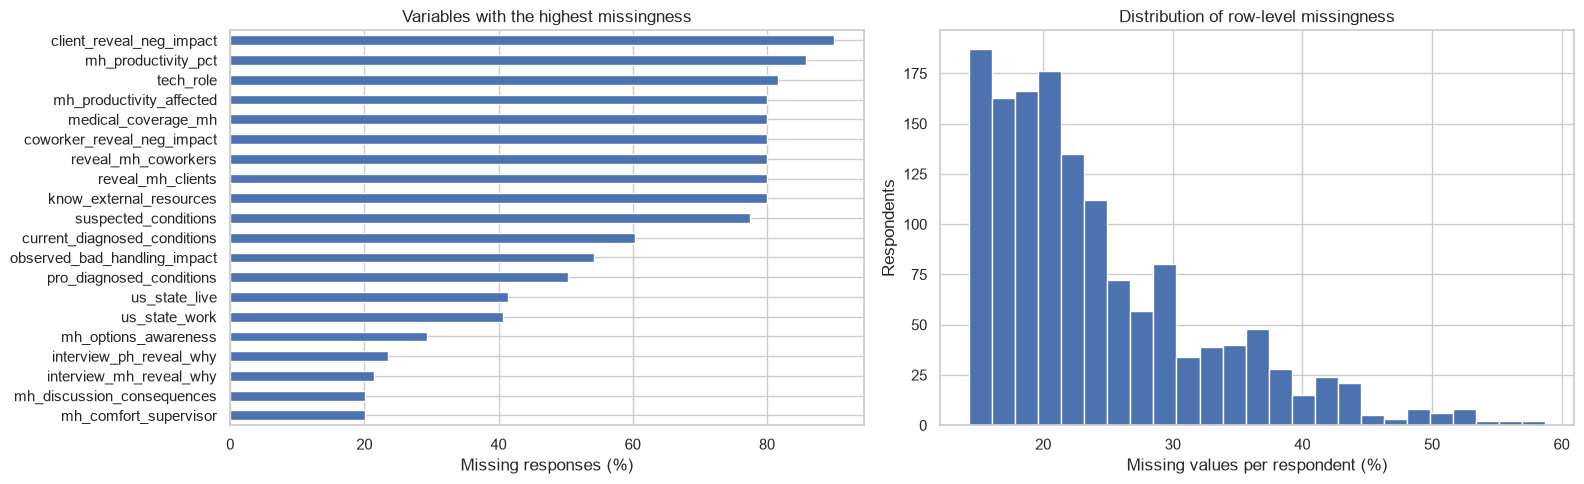

In [5]:
missing_by_column = (
    df.isna().sum().rename("missing_count").to_frame()
    .assign(missing_pct=lambda x: (x["missing_count"] / len(df) * 100).round(2))
    .sort_values("missing_count", ascending=False)
)

display(missing_by_column.head(25))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
missing_by_column.head(20)["missing_pct"].sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Variables with the highest missingness")
axes[0].set_xlabel("Missing responses (%)")

row_missing_pct = df.isna().mean(axis=1).mul(100)
axes[1].hist(row_missing_pct, bins=25, edgecolor="white")
axes[1].set_title("Distribution of row-level missingness")
axes[1].set_xlabel("Missing values per respondent (%)")
axes[1].set_ylabel("Respondents")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "row-level-missingness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Missingness is concentrated in conditional follow-up questions rather than being evenly distributed. For example, follow-ups about disclosure impact, productivity percentage, and employer/previous-employer experiences are only relevant to subsets of respondents. Treating every blank as the same kind of missing value would erase survey logic. Notebook 02 will distinguish structural non-applicability from unanswered items and will not globally fill every missing string.

## 6. Survey Routing and Conditional-Question Checks

In [6]:
# Employment routing: employer questions are not asked of self-employed respondents.
for target in [
    "mh_benefits",
    "tech_company",
    "company_size",
    "medical_coverage_mh"
]:
    if target in df.columns:
        print(f"\nself_employed x missing({target})")
        display(
            pd.crosstab(
                df["self_employed"],
                df[target].isna(),
                margins=True
            )
        )

# Previous-employer routing.
print("\nhas_previous_employers x missing(prev_mh_benefits)")
display(
    pd.crosstab(
        df["has_previous_employers"],
        df["prev_mh_benefits"].isna(),
        margins=True
    )
)

# Productivity follow-up routing.
print("\nmh_productivity_affected x missing(mh_productivity_pct)")
display(
    pd.crosstab(
        df["mh_productivity_affected"],
        df["mh_productivity_pct"].isna(),
        margins=True,
        dropna=False
    )
)

# Current diagnosis/suspected-condition follow-up routing.
for target in ["current_diagnosed_conditions", "suspected_conditions"]:
    print(f"\ncurrent_mh_disorder x missing({target})")
    display(
        pd.crosstab(
            df["current_mh_disorder"],
            df[target].isna(),
            margins=True,
            dropna=False
        )
    )


self_employed x missing(mh_benefits)


mh_benefits,False,True,All
self_employed,,,
0,1146,0,1146
1,0,287,287
All,1146,287,1433



self_employed x missing(tech_company)


tech_company,False,True,All
self_employed,,,
0,1146,0,1146
1,0,287,287
All,1146,287,1433



self_employed x missing(company_size)


company_size,False,True,All
self_employed,,,
0,1146,0,1146
1,0,287,287
All,1146,287,1433


... (6 outputs left out)


current_mh_disorder x missing(current_diagnosed_conditions)


current_diagnosed_conditions,False,True,All
current_mh_disorder,,,
Maybe,0,327,327
No,0,531,531
Yes,568,7,575
All,568,865,1433



current_mh_disorder x missing(suspected_conditions)


suspected_conditions,False,True,All
current_mh_disorder,,,
Maybe,322,5,327
No,0,531,531
Yes,0,575,575
All,322,1111,1433


The routing tables demonstrate why missing values cannot be indiscriminately replaced. Employer-related fields are structurally absent for self-employed respondents; previous-employer questions are absent for respondents without previous employers; and condition/productivity follow-ups depend on earlier answers. A particularly important detail is that `medical_coverage_mh` is answered by the self-employed branch in this dataset, while several other employer fields are answered by the non-self-employed branch. Notebook 02 must follow the observed survey routing, not apply a blanket rule to every employer-related field.

## 7. Age Quality and Outlier Inspection

count    1433.000000
mean       34.286113
std        11.290931
min         3.000000
25%        28.000000
50%        33.000000
75%        39.000000
max       323.000000
Name: age, dtype: float64


,age,gender
93,17,male
372,99,Other
564,323,Male
656,3,Male
808,15,male


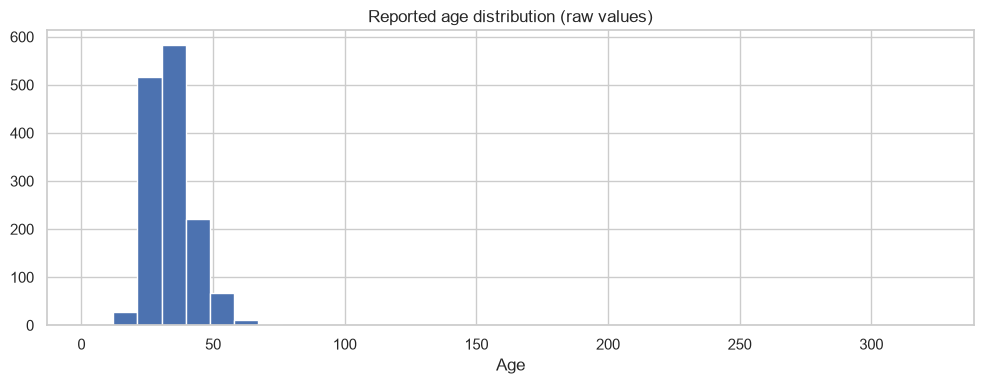

In [7]:
print(df["age"].describe())
age_review = df.loc[~df["age"].between(18, 75), ["age", "gender"]]
display(age_review)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df["age"].dropna(), bins=35, edgecolor="white")
ax.set_title("Reported age distribution (raw values)")
ax.set_xlabel("Age")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "age-distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The raw age field has a central tendency around the low-to-mid thirties, but includes extreme reported values. In this source, values 3 and 323 are implausible as respondent ages and will be flagged as invalid in preparation. Values such as 15, 17, and 99 are unusual but cannot be declared erroneous from the data alone; they will be retained and documented rather than automatically replaced. Age is contextual and is not part of the primary workplace-climate clustering feature set.

## 8. Gender Response Quality

In [8]:
gender_counts = (
    df["gender"]
    .value_counts(dropna=False)
    .rename_axis("raw_gender")
    .to_frame("frequency")
)

display(gender_counts)
print(
    "Missing gender responses:",
    int(df["gender"].isna().sum())
)
print("Gender values containing a pipe delimiter:")
display(
    df.loc[
        df["gender"].astype("string").str.contains(r"\|", na=False),
        ["gender"]
    ]
)

,frequency
raw_gender,
Male,610
male,249
Female,153
female,95
M,86
m,79
F,38
f,23
Male,11


Missing gender responses: 3
Gender values containing a pipe delimiter:


,gender
925,M|


Gender is recorded through open-text responses, producing many spelling, capitalization, abbreviation, and identity variants. It should not be treated as a clean low-cardinality nominal feature without normalization. The preparation notebook canonicalizes only unambiguous variants (for example, `M`/`male` and `F`/`female`) and preserves other self-descriptions rather than forcing them into binary categories. Gender is excluded from the primary clustering inputs.

## 9. Multi-Select Responses and Free Text

In [9]:
MULTI_SELECT_COLUMNS = [
    "current_diagnosed_conditions",
    "suspected_conditions",
    "pro_diagnosed_conditions",
    "work_position",
]

for col in MULTI_SELECT_COLUMNS:
    values = df[col].dropna().astype(str)
    pipe_rows = values.str.contains(r"\|", regex=True).sum()
    tokens = values.str.split("|").explode().str.strip()
    
    print(
        f"{col}: {pipe_rows:,} pipe-delimited rows; "
        f"{tokens.nunique():,} distinct tokens"
    )
    display(tokens.value_counts().head(12).to_frame("frequency"))

for col in [
    "interview_ph_reveal_why",
    "interview_mh_reveal_why"
]:
    print(
        f"\n{col}: {df[col].notna().sum():,} non-missing responses; "
        f"{df[col].nunique(dropna=True):,} distinct responses"
    )
    display(
        df[col]
        .dropna()
        .astype(str)
        .str.strip()
        .value_counts()
        .head(10)
        .to_frame("frequency")
    )

current_diagnosed_conditions: 367 pipe-delimited rows; 33 distinct tokens


,frequency
current_diagnosed_conditions,
"Mood Disorder (Depression, Bipolar Disorder, etc)",412
"Anxiety Disorder (Generalized, Social, Phobia, etc)",345
Attention Deficit Hyperactivity Disorder,121
Post-traumatic Stress Disorder,69
Obsessive-Compulsive Disorder,45
Substance Use Disorder,39
Stress Response Syndromes,38
"Personality Disorder (Borderline, Antisocial, Paranoid, etc)",35
Addictive Disorder,35


suspected_conditions: 207 pipe-delimited rows; 23 distinct tokens


,frequency
suspected_conditions,
"Mood Disorder (Depression, Bipolar Disorder, etc)",219
"Anxiety Disorder (Generalized, Social, Phobia, etc)",192
Attention Deficit Hyperactivity Disorder,58
"Personality Disorder (Borderline, Antisocial, Paranoid, etc)",42
Stress Response Syndromes,40
Obsessive-Compulsive Disorder,30
Post-traumatic Stress Disorder,26
Addictive Disorder,24
Substance Use Disorder,16


pro_diagnosed_conditions: 392 pipe-delimited rows; 34 distinct tokens


,frequency
pro_diagnosed_conditions,
"Mood Disorder (Depression, Bipolar Disorder, etc)",526
"Anxiety Disorder (Generalized, Social, Phobia, etc)",373
Attention Deficit Hyperactivity Disorder,134
Post-traumatic Stress Disorder,70
Obsessive-Compulsive Disorder,40
Stress Response Syndromes,31
"Personality Disorder (Borderline, Antisocial, Paranoid, etc)",28
Substance Use Disorder,26
"Eating Disorder (Anorexia, Bulimia, etc)",18


... (2 outputs left out)


interview_ph_reveal_why: 1,095 non-missing responses; 1,085 distinct responses


,frequency
interview_ph_reveal_why,
Not relevant,3
Fear of discrimination,3
I don't know,3
Fear of not getting the job,3
None of their business,2
None of their business.,2
bias,2
honesty,2
"It would depend on the health issue. If there is a health issue that would not immediately affect my job performance, such as diabetes, I would not bring it up during the interview. If it was something more severe, such as narcolepsy, I might bring it up depending on how controlled it was.",1



interview_mh_reveal_why: 1,126 non-missing responses; 1,080 distinct responses


,frequency
interview_mh_reveal_why,
Stigma,14
Stigma.,10
Same as above,7
See above,4
Fear of discrimination,4
Fear of not getting the job,4
Same reason as above.,3
same as above,3
Same as above.,3


`current_diagnosed_conditions`, `suspected_conditions`, `pro_diagnosed_conditions`, and `work_position` contain pipe-delimited multi-select answers. They are not single categorical labels: each option is a separate selection. The condition fields are sensitive and will be parsed for data-quality auditing but excluded from clustering. `work_position` will be tokenized into supplementary indicators, not treated as a single pipe-string category. The two interview-reason fields are free text with high cardinality; they are excluded from the primary clustering analysis because an NLP feature pipeline is outside the stated objective and would introduce additional privacy and modelling decisions.

## 10. Geographic and Work-Arrangement Context

In [10]:
print(
    "Respondents whose country of residence differs from country of work:",
    int(
        (
            df["country_live"].notna()
            & df["country_work"].notna()
            & df["country_live"].ne(df["country_work"])
        ).sum()
    )
)

display(
    pd.crosstab(
        df["country_live"],
        df["country_work"],
        margins=True
    ).iloc[:12, :12]
)

for col in ["us_state_live", "us_state_work"]:
    print(f"{col}: {df[col].isna().sum():,} missing")

display(
    df["work_remote"]
    .value_counts(dropna=False)
    .to_frame("frequency")
)

Respondents whose country of residence differs from country of work: 26


country_work,Afghanistan,Argentina,Australia,Austria,Bangladesh,Belgium,Bosnia and Herzegovina,Brazil,Brunei,Bulgaria,Canada,Chile
country_live,,,,,,,,,,,,
Afghanistan,1,0,0,0,0,0,0,0,0,0,0,0
Algeria,0,0,0,0,0,0,0,0,0,0,0,0
Argentina,0,1,0,0,0,0,0,0,0,0,0,0
Australia,0,0,34,0,0,0,0,0,0,0,0,0
Austria,0,0,0,4,0,0,0,0,0,0,0,0
Bangladesh,0,0,0,0,1,0,0,0,0,0,0,0
Belgium,0,0,0,0,0,5,0,0,0,0,0,0
Bosnia and Herzegovina,0,0,0,0,0,0,2,0,0,0,0,0
Brazil,0,0,0,0,0,0,0,10,0,0,0,0


us_state_live: 593 missing
us_state_work: 582 missing


,frequency
work_remote,
Sometimes,757
Always,343
Never,333


Country and US-state fields are contextual, geographically dependent variables with substantial cardinality and structural missingness outside the United States. They are not suitable for direct inclusion in the primary workplace-climate clusters. Remote-work frequency is an ordered response (`Never`, `Sometimes`, `Always`) and will be typed as ordinal in the full cleaned dataset, but is not one of the 15 primary clustering features.

## 11. Preliminary Feature Scope and Preparation Decisions

In [11]:
# Cohort rule used for the primary workplace-climate analysis.
cohort_mask = (
    df["self_employed"].eq(0)
    & (df["tech_company"].eq(1) | df["tech_role"].eq(1))
)
cohort = df.loc[cohort_mask].copy()

print(f"Eligible analytical cohort: {len(cohort):,} / {len(df):,} respondents")
print("Cohort definition: non-self-employed AND (tech employer OR tech/IT role)")

FEATURES_BY_DOMAIN = {
    "employer_support": [
        "mh_benefits",
        "mh_formal_discussion",
        "mh_resources_offered",
        "mh_anonymity_protected",
        "mh_medical_leave_ease",
        "mh_vs_ph_seriousness",
    ],
    "psychological_safety": [
        "mh_discussion_consequences",
        "ph_discussion_consequences",
        "mh_comfort_coworkers",
        "mh_comfort_supervisor",
        "observed_mh_consequences",
    ],
    "disclosure_career_climate": [
        "interview_ph_reveal",
        "interview_mh_reveal",
        "mh_hurt_career",
        "coworker_negative_view",
    ],
}

PRIMARY_FEATURES = [
    c for group in FEATURES_BY_DOMAIN.values()
    for c in group
]

feature_overview = pd.DataFrame({
    "domain": [
        domain for domain, cols in FEATURES_BY_DOMAIN.items()
        for _ in cols
    ],
    "feature": PRIMARY_FEATURES,
    "unique_in_cohort": [
        cohort[c].nunique(dropna=True) for c in PRIMARY_FEATURES
    ],
    "missing_in_cohort": [
        cohort[c].isna().sum() for c in PRIMARY_FEATURES
    ],
})

display(feature_overview)

Eligible analytical cohort: 1,131 / 1,433 respondents
Cohort definition: non-self-employed AND (tech employer OR tech/IT role)


,domain,feature,unique_in_cohort,missing_in_cohort
0,employer_support,mh_benefits,4,0
1,employer_support,mh_formal_discussion,3,0
2,employer_support,mh_resources_offered,3,0
3,employer_support,mh_anonymity_protected,3,0
4,employer_support,mh_medical_leave_ease,6,0
5,employer_support,mh_vs_ph_seriousness,3,0
6,psychological_safety,mh_discussion_consequences,3,0
7,psychological_safety,ph_discussion_consequences,3,0
8,psychological_safety,mh_comfort_coworkers,3,0
9,psychological_safety,mh_comfort_supervisor,3,0


### Data-Understanding Conclusions

The source contains 1,433 records and 63 variables. The primary analytical cohort is defined transparently as respondents who are not self-employed and who report either a technology employer or a technology/IT role. The rule yields **1,131 respondents** in the supplied file.

The primary feature scope contains **15 workplace-climate questions** across three conceptually distinct domains: employer support, psychological safety, and disclosure/career climate. Personal diagnosis/treatment variables, demographic attributes, country/state, free text, and work-position selections are excluded from the primary clustering matrix. They are not silently discarded from the source; their treatment is documented in Notebook 02.

The four clustering methods require different representations. K-Modes and MCA + K-Means receive categorical inputs; both treat the medical-leave response nominally in the model space, so ordinal spacing is not preserved for those two methods. Agglomerative and HDBSCAN receive Gower dissimilarities, for which the medical-leave response is explicitly rank-scaled and the “I don't know” response remains an unordered category. No global scaling is needed for nominal features.

In [12]:
# Persist a renamed, non-cleaned interim copy for Notebook 02.
renamed_path = Path(INTERIM_DIR) / "osmi_2016_renamed_interim.csv"
df.to_csv(renamed_path, index=False)
print(f"Saved renamed interim dataset (no substantive cleaning): {renamed_path}")

Saved renamed interim dataset (no substantive cleaning): C:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\data\interim\osmi_2016_renamed_interim.csv


**Handoff to Notebook 02.** The exported file contains the original observations with standardized column names only. It is an interim analytical copy, not a cleaned dataset. Notebook 02 begins from this file, performs the documented preparation, validates each representation, and writes model-ready artifacts.